# Município vs Ajuste Direto

How much of municipal procurement is direct award, by **count** and by **value**?

- **Município:** adjudicante name, accent-folded and lowercased, starts with `municipio` (93 516 rows, 309 NIPC).
- **Ajuste Direto:** `tipo_procedimento` lowercased starts with `ajuste direto` (180 174 rows).

Caveats: 309 NIPCs vs 308 municipalities (at least one false positive); `Câmara Municipal …` is excluded.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import is_municipio_expr, load_contracts
from base_gov.entities import (
    canonical_names,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()

rows=643,548  cols=31
disregarded 2,307 contracts with |preco_contratual| < €10 (0.36%); kept 641,241
valor_por_dia defined for 99.0% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)


idcontrato,ano,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,desc_contrato,preco_contratual,preco_total_efetivo,preco_base_procedimento,prazo_execucao,valor_por_dia,data_celebracao,data_publicacao,data_fecho,tipo_contrato,tipo_procedimento,fundament_ajuste_direto,cpv,nuts,concorrentes,TipoCriterioAdjudicacao,n_concorrentes,is_municipio,is_below_min_value,row_hash,first_ingested_at,updated_at
i64,i32,str,str,str,str,str,str,str,str,f64,f64,f64,i64,f64,date,date,date,str,str,str,str,str,str,str,u32,bool,bool,i64,"datetime[μs, UTC]","datetime[μs, UTC]"
11051950,2024,"""501413197 - Universidade do Po…","""501413197""","""Universidade do Porto - Faculd…","""501413197""","""nipc""","""500126623 - Gertal - Companhia…","""Aquisição de refeições confeci…","""Aquisição de refeições confeci…",3.8767e6,0.0,4.5642e6,364,10650.394368,2024-11-12,2024-11-27,null,"""Aquisição de bens móveis""","""Concurso público""",null,"""15894200-3 - Refeições prepara…","""PT11A - Área Metropolitana do …","""501323325-Uniself - Sociedade …","""Monofator""",4,false,false,-3226272757099977435,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11060512,2024,"""501442600 - Instituto do Empre…","""501442600""","""Instituto do Emprego e da Form…","""501442600""","""nipc""","""- - Pedro Emanuel Ribeiro da R…","""Serviços de Formação Profissio…","""AQUISIÇÃO SERVIÇOS DE FORMAÇÃO…",5000.0,5000.0,5000.0,365,13.69863,2024-09-03,2024-12-03,2025-05-23,"""Aquisição de serviços""","""Contratação excluída II""",null,"""80530000-8 - Serviços de forma…",null,"""--Pedro Emanuel Ribeiro da Roc…","""Monofator""",1,false,false,-2579447276048904472,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11064174,2024,"""506803228 - ATEC - Associação …","""506803228""","""ATEC - Associação de Formação …","""506803228""","""nipc""","""516273302 - AM-Ferramentas de …","""Aquisição de material para Mec…","""Aquisição de material para Mec…",94388.61,0.0,108500.0,730,129.299466,2024-12-04,2024-12-04,null,"""Aquisição de bens móveis""","""Concurso público""",null,"""34300000-0 - Peças e acessório…","""PTZZZ - Extra-Regio NUTS 3 (To…","""510953859-PBTOOLS - unipessoal…","""Multifator""",7,false,false,-4867324996322863534,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11089864,2024,"""506362299 - Instituto Portuguê…","""506362299""","""Instituto Português de Oncolog…","""506362299""","""nipc""","""500039720 - AVIQUÍMICA - IMPOR…","""TOALHETE DESINFETANTE PARA SUP…","""41411524 - TOALHETE DESINFETAN…",191.52,0.0,191.52,20,9.576,2024-10-17,2024-12-16,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""33000000-0 - Equipamento médic…","""PT11A - Área Metropolitana do …",null,"""Monofator""",null,false,false,6174870913128464768,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11045330,2024,"""501510184 - ISCTE - Instituto …","""501510184""","""ISCTE - Instituto Universitári…","""501510184""","""nipc""","""501364668 - Seleprinter - Soci…","""AQUISIÇÃO DE FOLHETOS PARA O I…","""AQUISIÇÃO DE FOLHETOS PARA O I…",200.0,200.0,200.0,60,3.333333,2024-10-30,2024-11-25,2024-12-06,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""22140000-3 - Folhetos""",null,null,"""Monofator""",null,false,false,-1631265789765637343,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC


In [3]:
AD_EXPR = pl.col("tipo_procedimento").str.to_lowercase().str.starts_with("ajuste direto")

In [4]:
contracts = contracts.with_columns(
    is_municipio_expr().alias("is_municipio"),
    AD_EXPR.alias("is_ajuste_direto"),
)
print(f"Município: {contracts['is_municipio'].sum():,}  Ajuste Direto: {contracts['is_ajuste_direto'].sum():,}")


Município: 150,103  Ajuste Direto: 292,418


In [5]:
cross = (
    contracts.group_by("is_municipio", "is_ajuste_direto")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("is_municipio", "is_ajuste_direto")
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum().over("is_municipio") * 100).round(1).alias("row_pct_count"),
        (pl.col("total_value") / pl.col("total_value").sum().over("is_municipio") * 100).round(1).alias("row_pct_value"),
        (pl.col("n_contracts") / pl.col("n_contracts").sum().over("is_ajuste_direto") * 100).round(1).alias("col_pct_count"),
    )
)
assert cross["n_contracts"].sum() == contracts.height
for r in cross.iter_rows(named=True):
    print(f"municipio={r['is_municipio']!s:5} ad={r['is_ajuste_direto']!s:5} n={r['n_contracts']:>8,} value=€{r['total_value'] / 1e6:>10,.1f}M")
cross


municipio=False ad=False n= 272,318 value=€  36,604.7M
municipio=False ad=True  n= 218,820 value=€   6,480.9M
municipio=True  ad=False n=  76,505 value=€  11,958.5M
municipio=True  ad=True  n=  73,598 value=€   1,569.4M


is_municipio,is_ajuste_direto,n_contracts,total_value,row_pct_count,row_pct_value,col_pct_count
bool,bool,u32,f64,f64,f64,f64
false,false,272318,3.6605e10,55.4,85.0,78.1
false,true,218820,6.4809e9,44.6,15.0,74.8
true,false,76505,1.1959e10,51.0,88.4,21.9
true,true,73598,1.5694e9,49.0,11.6,25.2


In [6]:
def procedure_mix(df: pl.DataFrame) -> pl.DataFrame:
    return (
        df.group_by("tipo_procedimento")
        .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
        .with_columns(
            (pl.col("n_contracts") / pl.col("n_contracts").sum() * 100).round(1).alias("pct_count"),
            (pl.col("total_value") / pl.col("total_value").sum() * 100).round(1).alias("pct_value"),
        )
        .sort("n_contracts", descending=True)
    )


mun = contracts.filter(pl.col("is_municipio"))
rest = contracts.filter(~pl.col("is_municipio"))
mun_mix = procedure_mix(mun)
ad_mun = mun.filter(pl.col("is_ajuste_direto"))
print(f"Município Ajuste Direto: {ad_mun.height:,} rows = {ad_mun.height / mun.height:.1%} by count, "
      f"{ad_mun['preco_contratual'].sum() / mun['preco_contratual'].sum():.1%} by value")
mun_mix


Município Ajuste Direto: 73,598 rows = 49.0% by count, 11.6% by value


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",73529,1.5686e9,49.0,11.6
"""Consulta Prévia""",43128,1.5855e9,28.7,11.7
"""Concurso público""",27131,8.6636e9,18.1,64.0
"""Contratação excluída II""",2357,2.8761e8,1.6,2.1
"""Ao abrigo de acordo-quadro (ar…",1724,4.6157e8,1.1,3.4
"""Ao abrigo de acordo-quadro (ar…",1555,4.3209e8,1.0,3.2
"""Consulta Prévia Simplificada""",435,6.2199e7,0.3,0.5
"""Concurso limitado por prévia q…",101,3.5483e8,0.1,2.6
"""Ajuste direto simplificado ao …",63,546252.51,0.0,0.0


In [7]:
# Effect of disregarding contracts with |value| below €10 on the two groups being compared.
all_flags = contracts_all.with_columns(is_municipio_expr().alias("is_municipio"), AD_EXPR.alias("is_ajuste_direto"))
print("Município:")
display(value_impact(all_flags.filter(pl.col("is_municipio")), mun))
print("Município Ajuste Direto:")
display(value_impact(all_flags.filter(pl.col("is_municipio") & pl.col("is_ajuste_direto")), ad_mun))

Município:


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",150391.0,150103.0,-288.0,-0.19
"""mean_value""",89951.341098,90123.928485,172.587387,0.19
"""median_value""",18450.0,18500.0,50.0,0.27
"""total_value""",1.3528e10,1.3528e10,-101.700001,-0.0


Município Ajuste Direto:


metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",73720.0,73598.0,-122.0,-0.17
"""mean_value""",21288.123778,21323.410948,35.28717,0.17
"""median_value""",12000.0,12000.0,0.0,0.0
"""total_value""",1.5694e9,1.5694e9,-85.97,-0.0


In [8]:
# Duration and value per day: Município Ajuste Direto vs other Município procedures vs rest.
groups = {"município AD": ad_mun, "município other": mun.filter(~pl.col("is_ajuste_direto")), "rest": rest}
display(pl.DataFrame([
    {"group": k, "n": g.height, "median_prazo_days": g["prazo_execucao"].median(),
     "median_value": g["preco_contratual"].median(), "median_eur_per_day": g["valor_por_dia"].median(),
     "value_per_day_defined": round(g["valor_por_dia"].is_not_null().mean(), 3)}
    for k, g in groups.items()
]))

group,n,median_prazo_days,median_value,median_eur_per_day,value_per_day_defined
str,i64,f64,f64,f64,f64
"""município AD""",73598,60.0,12000.0,191.166667,0.98
"""município other""",76505,180.0,38400.0,281.166667,0.996
"""rest""",491138,123.0,9349.76,85.743447,0.991


In [9]:
print("Non-Município adjudicantes:")
rest_mix = procedure_mix(rest)
rest_mix


Non-Município adjudicantes:


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",217003,6.4730e9,44.2,15.0
"""Ao abrigo de acordo-quadro (ar…",81324,7.2026e9,16.6,16.7
"""Concurso público""",71739,2.0919e10,14.6,48.6
"""Consulta Prévia""",66876,2.1126e9,13.6,4.9
"""Contratação excluída II""",31672,2.0863e9,6.4,4.8
"""Ao abrigo de acordo-quadro (ar…",14646,9.7608e8,3.0,2.3
"""Setores especiais – isenção pa…",3297,2.1837e8,0.7,0.5
"""Ajuste direto simplificado ao …",1721,7.0734e6,0.4,0.0
"""Concurso limitado por prévia q…",1427,1.7130e9,0.3,4.0


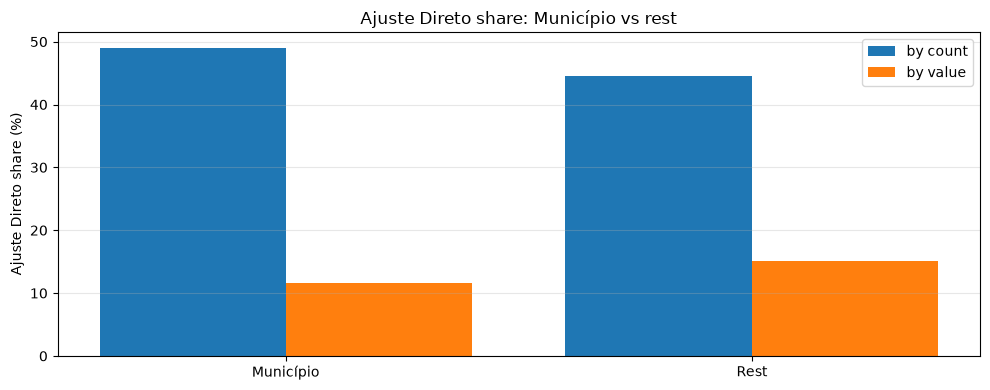

In [10]:
import numpy as np

def ad_shares(df: pl.DataFrame) -> tuple[float, float]:
    ad = df.filter(pl.col("is_ajuste_direto"))
    return ad.height / df.height * 100, ad["preco_contratual"].sum() / df["preco_contratual"].sum() * 100

shares = {"Município": ad_shares(mun), "Rest": ad_shares(rest)}
x = np.arange(2)
fig, ax = plt.subplots()
ax.bar(x - 0.2, [s[0] for s in shares.values()], 0.4, label="by count")
ax.bar(x + 0.2, [s[1] for s in shares.values()], 0.4, label="by value")
ax.set_xticks(x, list(shares))
ax.set_ylabel("Ajuste Direto share (%)")
ax.set_title("Ajuste Direto share: Município vs rest")
ax.legend()
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()


In [11]:
per_mun = (
    mun.group_by("adjudicante_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("is_ajuste_direto").mean().alias("ad_share"),
    )
    .filter(pl.col("n_contracts") >= 50)  # avoid small-denominator noise
    .join(canonical_names(mun, prefix="adjudicante"), on="adjudicante_key", how="left")
)
assert per_mun["ad_share"].is_between(0, 1).all()
print(f"{per_mun.height} municipalities with >= 50 contracts")
print("Highest AD share:")
display(per_mun.sort("ad_share", descending=True).head(15))
print("\nLowest AD share:")
display(per_mun.sort("ad_share").head(15))


305 municipalities with >= 50 contracts
Highest AD share:


adjudicante_key,n_contracts,ad_share,adjudicante_name
str,u32,f64,str
"""512073821""",234,0.92735,"""Município da Horta"""
"""512074089""",66,0.924242,"""Município de Calheta São Jorge"""
"""512074410""",458,0.923581,"""Município de Lagoa (Açores)"""
"""512043701""",148,0.918919,"""Município de Vila Franca do Ca…"
"""512044023""",199,0.879397,"""Município da Praia da Vitória"""
"""500832935""",139,0.755396,"""Município de Cuba"""
"""506659968""",254,0.748031,"""Município do Crato"""
"""506824942""",371,0.743935,"""Município de Sabrosa"""
"""506608972""",861,0.739837,"""Município de Torres Novas"""



Lowest AD share:


adjudicante_key,n_contracts,ad_share,adjudicante_name
str,u32,f64,str
"""512070946""",110,0.163636,"""Município da Madalena"""
"""505211696""",407,0.201474,"""Município de Arcos de Valdevez"""
"""505377802""",372,0.201613,"""Município de Proença-a-Nova"""
"""506215547""",535,0.224299,"""Município de Bragança"""
"""512074143""",158,0.234177,"""Município das Lajes do Pico"""
"""506641376""",636,0.234277,"""Município de Vila Verde"""
"""506843190""",254,0.240157,"""Município de Armamar"""
"""506808122""",454,0.246696,"""Município de Arouca"""
"""506854299""",402,0.248756,"""Município de Baião"""


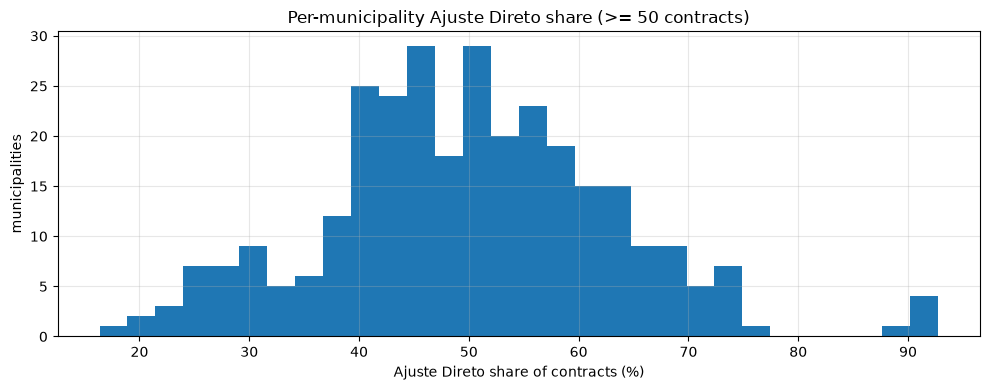

In [12]:
fig, ax = plt.subplots()
ax.hist(per_mun["ad_share"].to_numpy() * 100, bins=30)
ax.set_xlabel("Ajuste Direto share of contracts (%)")
ax.set_ylabel("municipalities")
ax.set_title("Per-municipality Ajuste Direto share (>= 50 contracts)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:
(
    mun.group_by("is_ajuste_direto")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("preco_contratual").mean().alias("mean_value"),
        pl.col("preco_contratual").sum().alias("total_value"),
    )
    .sort("is_ajuste_direto")
)


is_ajuste_direto,n_contracts,median_value,mean_value,total_value
bool,u32,f64,f64,f64
false,76505,38400.0,156310.197222,1.1959e10
true,73598,12000.0,21323.410948,1.5694e9


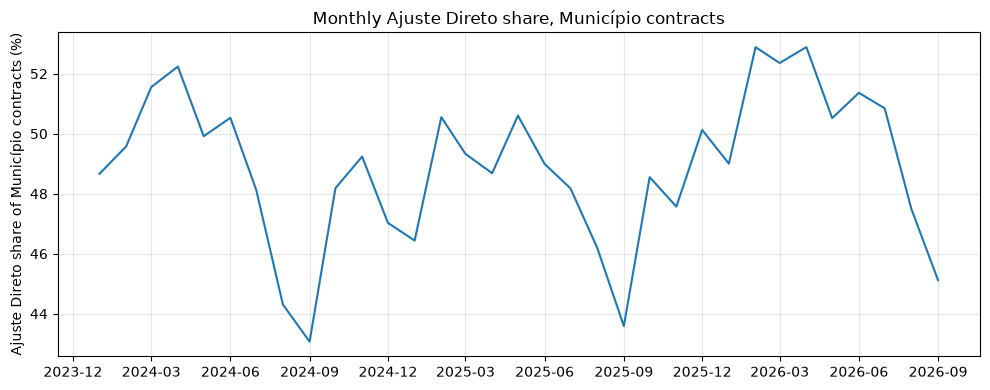

In [14]:
mm = (
    mun.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg((pl.col("is_ajuste_direto").mean() * 100).alias("ad_share"), pl.len().alias("n_contracts"))
    .sort("month")
)
fig, ax = plt.subplots()
ax.plot(mm["month"], mm["ad_share"])
ax.set_ylabel("Ajuste Direto share of Município contracts (%)")
ax.set_title("Monthly Ajuste Direto share, Município contracts")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Commentary and limitations

Direct award dominates municipal procurement by **count** (about half of contracts) but far less by **value**
(about an eighth): many small contracts go through Ajuste Direto while the large spend goes through
competitive procedures.

Limitations: 2025–2026 only (partial edge months); the Município rule may include false positives;
no per-contract legal-threshold validation.
Municipalities are keyed by NIPC (`adjudicante_key`), so the `>= 50` filter now counts each entity once
instead of once per name spelling.


Contracts with |value| below €10 are disregarded; `valor_por_dia` uses only 1–3650-day durations.